<br>
<br>

# `#01: Receptive Fields`

<br>
<br>

**Here, we design the CNN. But the question is when we design a CNN like this. Then how many layers there will be? It's depend on our tasks and the value of Receptive Fields. For a image detetion we want that our receptive must cover the whole image.**

<br>


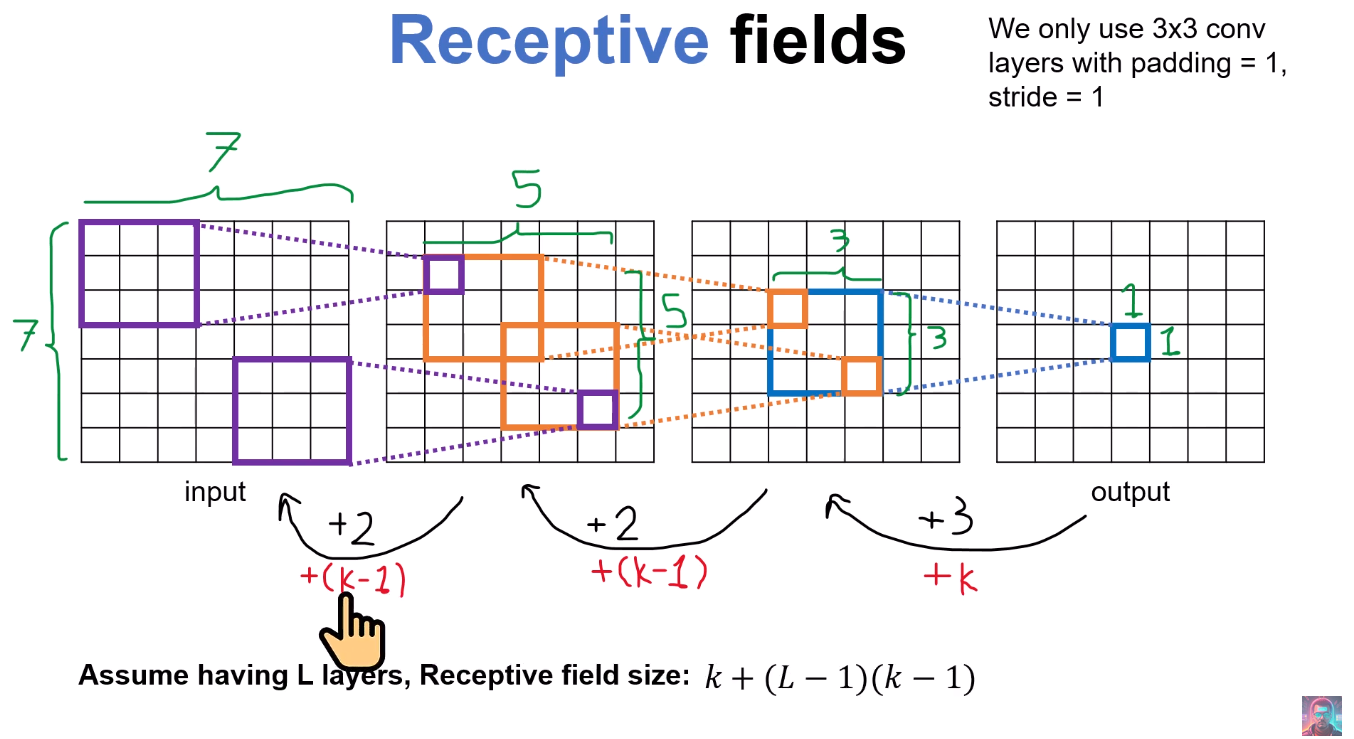

In [2]:
from IPython.display import Image
Image("../note/photo/image41.png")

In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F


def conv_bn(inp, oup, stride = 1, leaky = 0):
    return nn.Sequential(
        nn.Conv2d(inp, oup, 3, stride, 1, bias=False),
        nn.BatchNorm2d(oup),
        nn.LeakyReLU(negative_slope=leaky, inplace=True)
    )


def conv_dw(inp, oup, stride, leaky=0.1):
    return nn.Sequential(
        nn.Conv2d(inp, inp, 3, stride, 1, groups=inp, bias=False),
        nn.BatchNorm2d(inp),
        nn.LeakyReLU(negative_slope= leaky,inplace=True),

        nn.Conv2d(inp, oup, 1, 1, 0, bias=False),
        nn.BatchNorm2d(oup),
        nn.LeakyReLU(negative_slope= leaky,inplace=True),
    )


class MobileNetV1(nn.Module):
    def __init__(self):
        super(MobileNetV1, self).__init__()
        self.stage1 = nn.Sequential(
            # RF_new = RF_old + (k-1)*J_in, k=kernel size
            # J_in(all the stride multiplication with the current)
            conv_bn(3, 8, 2, leaky = 0.1),    # 3
            conv_dw(8, 16, 1),   # 3+(2*2)+(0*2)=7
            conv_dw(16, 32, 2),  # 7+(2*2)+0= 11
            conv_dw(32, 32, 1),  # 11+(2*4)+0 =19
            conv_dw(32, 64, 2),  # 19 +(2*4)+0 = 27
            conv_dw(64, 64, 1),  # 27 +(2*8)+0 = 43
        )
        self.stage2 = nn.Sequential(
            conv_dw(64, 128, 2),  # 43 + 16 = 59
            conv_dw(128, 128, 1), # 59 + 32 = 91
            conv_dw(128, 128, 1), # 91 + 32 = 123
            conv_dw(128, 128, 1), # 123 + 32 = 155
            conv_dw(128, 128, 1), # 155 + 32 = 187
            conv_dw(128, 128, 1), # 187 + 32 = 219
        )
        self.stage3 = nn.Sequential(
            conv_dw(128, 256, 2), # 219 +3 2 = 241
            conv_dw(256, 256, 1), # 241 + 64 = 301
        )
        self.avg = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(256, 1000)

    def forward(self, x):
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.avg(x)
        # x = self.model(x)
        x = x.view(-1, 256)
        x = self.fc(x)
        return x
